# 03 - Approval-time features and leakage checks
Every feature must be observable when the order is approved. Multi-row tables are aggregated per order before
joining. Historical aggregates use only orders whose **outcome was known (delivered) before** the scored order's
approval time - not merely orders approved earlier.

In [1]:
# Cell 1 - make the project package importable and define folders
import sys, os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ["PROJECT_ROOT"] = str(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT / "src"))
import numpy as np, pandas as pd, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 80)
from olist_risk import config
config.ensure_dirs()
print("PROJECT_ROOT =", PROJECT_ROOT)
print("outputs ->", config.OUTPUT_DIR)

PROJECT_ROOT = /home/sagemaker-user/ml-project2-v2
outputs -> /home/sagemaker-user/ml-project2-v2/outputs


In [2]:
# Cell 2 - load raw tables and labels
from olist_risk import data, features
t = data.load_raw()
lab = pd.read_pickle(config.PROCESSED_DIR / "labels.pkl")
print(lab.shape)

(99441, 19)


In [3]:
# Cell 3 - build the order-level feature table (one row per order)
import time
t0 = time.time()
ft = features.build_feature_table(t, lab)
print(f"feature table {ft.shape} built in {time.time() - t0:.1f}s")
assert ft.order_id.is_unique and len(ft) == len(t["orders"]), "join multiplied orders!"
print("one row per order_id: OK  |  predictors:", len(features.FEATURES),
      f"({len(features.NUM_FEATURES)} numeric, {len(features.CAT_FEATURES)} categorical)")

feature table (99441, 73) built in 18.2s
one row per order_id: OK  |  predictors: 49 (45 numeric, 4 categorical)


In [4]:
# Cell 4 - feature-availability audit (also saved for the report)
audit = features.feature_availability_audit()
audit.to_csv(config.TABLE_DIR / "03_feature_availability_audit.csv", index=False)
display(audit[["feature_or_field", "source", "observed_at", "used_as_predictor"]])

,feature_or_field,source,observed_at,used_as_predictor
0,approve_delay_hours,"orders.purchase, orders.approved_at",at/before approval,yes
1,promised_days,"orders.estimated_delivery_date, approved_at",at/before approval (promise shown at purchase),yes
2,promised_days_from_purchase,"orders.estimated_delivery_date, purchase",at/before approval,yes
3,days_to_shipping_limit,order_items.shipping_limit_date,at/before approval (seller hand-over deadline set when order is placed/appro...,yes
4,approval_hour / approval_dow / is_weekend_approval / purchase_hour,orders timestamps,at/before approval,yes
5,"n_items, n_products, n_sellers, total_price, total_freight, freight_ratio, m...",order_items (aggregated per order),at/before approval,yes
6,"total_weight_g, max_weight_g, total_volume_cm3, category_missing, main_category",products + translation via items,at/before approval (catalogue attributes),yes
7,"payment_type_main, n_payment_rows, max_installments, payment_value, used_vou...",order_payments (aggregated),at/before approval (payment is what gets approved),yes
8,"customer_state, seller_state, same_state, same_city","customers, sellers (main seller)",at/before approval,yes
9,"customer/seller lat-lng, distance_km, geo_missing",geolocation (median per zip prefix),at/before approval,yes


In [5]:
# Cell 5 - leakage unit test: recompute seller/customer history by brute force for 300 random orders
chk = features.verify_history_bruteforce(ft, lab, n=300)
summary = chk[["match_outcomes", "match_orders", "match_customer", "no_future_outcome"]].mean()
display(summary.to_frame("share_true"))
assert summary.min() == 1.0 and not chk.own_outcome_used.any()
chk.to_csv(config.TABLE_DIR / "03_leakage_bruteforce_check.csv", index=False)
print("All sampled history features use only outcomes observed before approval and never the order's own outcome.")

,share_true
match_outcomes,1.0
match_orders,1.0
match_customer,1.0
no_future_outcome,1.0


All sampled history features use only outcomes observed before approval and never the order's own outcome.


In [6]:
# Cell 6 - missing values per predictor (handled by median/constant imputation + missing indicators)
miss = ft.loc[ft.in_daily_pool, features.FEATURES].isna().mean().mul(100).round(2)
miss = miss[miss > 0].sort_values(ascending=False).rename("missing_%").to_frame()
miss.to_csv(config.TABLE_DIR / "03_feature_missingness.csv"); display(miss)

,missing_%
distance_km,1.12
seller_lat,0.84
seller_lng,0.84
max_weight_g,0.64
n_sellers,0.63
n_products,0.63
n_items,0.63
days_to_shipping_limit,0.63
max_item_price,0.63
total_price,0.63


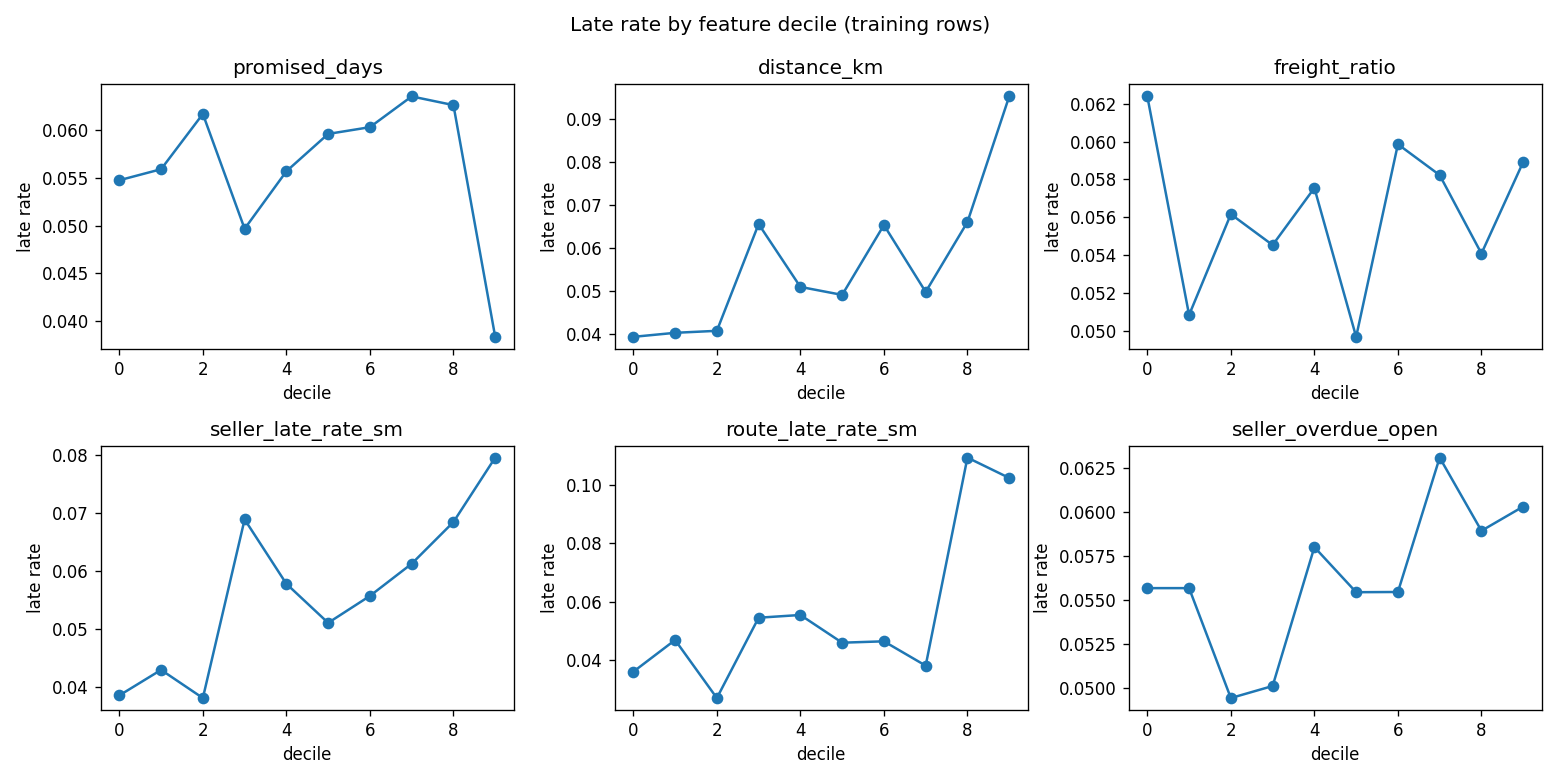

In [7]:
# Cell 7 - univariate signal: late rate by decile of selected features (training rows only)
tr = ft[ft.train_eligible]
cols = ["promised_days", "distance_km", "freight_ratio", "seller_late_rate_sm", "route_late_rate_sm", "seller_overdue_open"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, c in zip(axes.ravel(), cols):
    q = pd.qcut(tr[c].rank(method="first"), 10, labels=False)
    tr.groupby(q).is_late.mean().plot(ax=ax, marker="o"); ax.set_title(c); ax.set_xlabel("decile"); ax.set_ylabel("late rate")
fig.suptitle("Late rate by feature decile (training rows)"); fig.tight_layout()
fig.savefig(config.FIG_DIR / "03_late_rate_by_decile.png", dpi=120); plt.close(fig)
display(Image(str(config.FIG_DIR / "03_late_rate_by_decile.png")))

In [8]:
# Cell 8 - late rate by customer state (top 12 by volume, training rows)
g = tr.groupby("customer_state").agg(orders=("order_id", "size"), late_rate=("is_late", "mean")).sort_values("orders", ascending=False)
g.round(4).to_csv(config.TABLE_DIR / "03_late_rate_by_customer_state_train.csv"); display(g.head(12).round(4).T)

customer_state,SP,RJ,MG,RS,PR,SC,BA,ES,GO,DF,PE,CE
orders,17003.0000,5951.0000,5226.0000,2584.0000,2186.000,1647.0000,1521.0000,942.0000,912.0000,879.0000,728.0000,637.0000
late_rate,0.0379,0.1038,0.0272,0.0499,0.032,0.0753,0.0993,0.0743,0.0526,0.0432,0.0893,0.0832


In [9]:
# Cell 9 - descriptive statistics of the numeric predictors in the daily pool
desc = ft.loc[ft.in_daily_pool, features.NUM_FEATURES].describe().T.round(3)
desc.to_csv(config.TABLE_DIR / "03_feature_describe.csv"); display(desc.head(46))

,count,mean,std,min,25%,50%,75%,max
approve_delay_hours,98958.0,10.360,25.720,0.000,0.215,0.342,14.489,4509.181
promised_days,98958.0,23.786,8.682,-145.000,18.000,23.000,29.000,154.000
promised_days_from_purchase,98958.0,24.302,8.644,3.000,19.000,24.000,29.000,156.000
days_to_shipping_limit,98339.0,6.184,6.614,-6.400,4.000,6.000,6.000,1056.042
approval_hour,98958.0,12.736,6.605,0.000,8.000,14.000,18.000,23.000
approval_dow,98958.0,2.728,1.869,0.000,1.000,3.000,4.000,6.000
purchase_hour,98958.0,14.773,5.327,0.000,11.000,15.000,19.000,23.000
is_weekend_approval,98958.0,0.214,0.410,0.000,0.000,0.000,0.000,1.000
n_items,98339.0,1.142,0.538,1.000,1.000,1.000,1.000,21.000
n_products,98339.0,1.038,0.226,1.000,1.000,1.000,1.000,8.000


In [10]:
# Cell 10 - save the modeling table
ft.to_pickle(config.PROCESSED_DIR / "features.pkl")
print("saved", config.PROCESSED_DIR / "features.pkl", ft.shape)

saved /home/sagemaker-user/ml-project2-v2/data/processed/features.pkl (99441, 73)
